# Uplift on existing homes

> How much would the tunnel add to the value of the homes already there?

Homes closer to jobs cost more. If we can measure how much more, we can say what the tunnel's time savings are worth.

In [ ]:
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from fastcore.test import test_close, test_eq

from tunnel.access import attach_access
from tunnel.config import BNG, COLOURS, DERIVED, FIGURES, WGS84, use_style
from tunnel.data import MSOA_BOUNDARIES, OA_CENTROIDS, geocode, households, ons_layer, price_paid, thames

use_style()

## Elasticity

We'll assume price is proportional to travel time raised to some power $b$, the elasticity: a 1% shorter trip
means a home worth about $-b$% more. So a home whose trip falls from $t_0$ to $t_1$ gains $(t_1/t_0)^b - 1$.

In [ ]:
def uplift(before, after, b):
    "Proportional change in price when travel time goes from `before` to `after`, with elasticity `b`."
    return (after / before) ** b - 1

In [ ]:
test_eq(uplift(30, 30, -0.3), 0)
test_close(uplift(20, 10, -0.3), 2**0.3 - 1)  # halve the trip: +23%

Taking logs, $\log p = b \log t + \ldots$, so $b$ is the slope of a regression of log price on log time. With made-up
sales where we know the answer, regression gets it back:

In [ ]:
rng = np.random.default_rng(0)
fake = pd.DataFrame({"t": rng.uniform(5, 60, 2_000)})
fake["price"] = 400_000 * fake.t**-0.3 * np.exp(rng.normal(0, 0.3, len(fake)))
test_close(smf.ols("np.log(price) ~ np.log(t)", fake).fit().params["np.log(t)"], -0.3, eps=0.03)

Real prices depend on much else, so we also control for the type of home, whether it's new, its tenure, the year it
sold and how far it is from the river.

## Sales

Land Registry sales since 2018 in SE16 (Rotherhithe and Bermondsey), SE8 (Deptford), E14 (the Isle of Dogs) and E1W
(Wapping). We keep only standard sales (category A), dropping repossessions, portfolio sales and the like, and join
on travel times from notebook 03.

In [ ]:
DISTRICTS, SALES_FROM = ["SE16", "SE8", "E14", "E1W"], "2018-01-01"

sales = pd.concat([price_paid(d, SALES_FROM) for d in DISTRICTS], ignore_index=True)
sales["district"] = sales.postcode.str.split().str[0]  # the API matches prefixes, so SE1 would include SE16 etc.
sales = sales[
    sales.district.isin(DISTRICTS) & (sales.transaction_category == "A") & sales.property_type.isin(list("DSTF"))
]
sales = sales.drop_duplicates("unique_id").assign(
    price=lambda d: d.price_paid.astype(int), year=lambda d: pd.to_datetime(d.deed_date).dt.year
)
sales = sales.merge(geocode(sales.postcode.dropna().unique().tolist()), on="postcode", how="left").dropna(
    subset=["lon"]
)
sales = attach_access(gpd.GeoDataFrame(sales, geometry=gpd.points_from_xy(sales.lon, sales.lat), crs=WGS84))
keep = ["unique_id", "price", "year", "postcode", "district", "property_type", "new_build", "estate_type"]
sales = sales[keep + [c for c in sales if c.endswith(("_before", "_after"))] + ["geometry"]]
sales.drop(columns="geometry").to_csv(DERIVED / "sales.csv", index=False)
print(f"{len(sales):,} sales")
PROPERTY_TYPES = {"D": "detached", "S": "semi-detached", "T": "terraced", "F": "flat"}
summary = sales.assign(type=sales.property_type.map(PROPERTY_TYPES)).pivot_table(
    index="district", columns="type", values="price", aggfunc=["median", "size"]
)
summary.rename(columns={"median": "median price (£)", "size": "sales"}).reindex(
    columns=list(PROPERTY_TYPES.values()), level=1
).astype(int)

20,926 sales


median price (£)                                   sales  \
type             detached semi-detached terraced    flat detached   
district                                                            
E14               1200000        792500   687000  525000        3   
E1W               1125000        900000   872475  686226        5   
SE16               645000        722500   705000  450000        9   
SE8                793500        720000   637500  400000        4   

                                        
type     semi-detached terraced   flat  
district                                
E14                 44      525  11931  
E1W                  3      104   1969  
SE16                66      534   3376  
SE8                 20      327   2006

## Regression

Three versions. A compares all four districts directly. B adds a dummy for each district, so it only compares homes
within a district: this is our central case. C is B with cycling counted as open to everyone, so travel time is
whichever is quicker of the bike and walking or public transport.

In [ ]:
river = thames().union_all()
sales["log_price"] = np.log(sales.price)
sales["log_access"] = np.log(sales.access_before)
sales["log_multimodal"] = np.log(np.minimum(sales.access_before, sales.cycle_before))
sales["log_river"] = np.log(sales.distance(river))

CONTROLS = "C(property_type) + C(new_build) + C(estate_type) + C(year) + log_river"
SPECS = {"A": "log_access", "B": "log_access + C(district)", "C": "log_multimodal + C(district)"}
fit = lambda rhs: smf.ols(f"log_price ~ {rhs} + {CONTROLS}", sales).fit(
    cov_type="cluster", cov_kwds={"groups": sales.postcode}
)
models = {k: fit(rhs) for k, rhs in SPECS.items()}
b = {k: m.params.filter(like="log_").iloc[0] for k, m in models.items()}
pd.DataFrame(
    {k: {"elasticity": b[k], "s.e.": m.bse.filter(like="log_").iloc[0], "R²": m.rsquared} for k, m in models.items()}
).round(3)

,A,B,C
elasticity,-0.187,-0.310,-0.261
s.e.,0.027,0.028,0.032
R²,0.266,0.328,0.322


In the central case a 10% shorter trip goes with prices about 3% higher:

In [ ]:
f"{uplift(1, 0.9, b['B']):+.1%}"

'+3.3%'

## The housing stock

Census households by output area, each area valued at the median price of 2022+ sales within 500 m. Areas with no
nearby sales are outside our districts, so we drop them.

In [ ]:
oa = attach_access(ons_layer(OA_CENTROIDS).merge(households(), on="OA21CD"))
msoa = ons_layer(MSOA_BOUNDARIES).to_crs(BNG)
oa = gpd.sjoin(oa, msoa[["MSOA21NM", "geometry"]], predicate="within").drop(columns="index_right")
oa["borough"] = oa.MSOA21NM.str.rsplit(" ", n=1).str[0]

recent = sales[sales.year >= 2022][["price", "geometry"]]
near = gpd.sjoin(oa[["OA21CD", "geometry"]].assign(geometry=oa.buffer(500)), recent, predicate="contains")
oa["median_price"] = oa.OA21CD.map(near.groupby("OA21CD").price.median())
oa = oa.dropna(subset=["median_price"]).assign(stock_value=lambda d: d.households * d.median_price)
f"{oa.households.sum():,.0f} households worth £{oa.stock_value.sum() / 1e9:.1f}bn"

'130,970 households worth £65.1bn'

## Uplift

Low uses spec A, central spec B, and high spec C with cycling times. The high case assumes everyone would cycle, which
spreads the gain over a much wider area: read it as an upper bound.

In [ ]:
multimodal = lambda d, when: np.minimum(d[f"access_{when}"], d[f"cycle_{when}"])
scenarios = {
    "Low": uplift(oa.access_before, oa.access_after, b["A"]),
    "Central": uplift(oa.access_before, oa.access_after, b["B"]),
    "High": uplift(multimodal(oa, "before"), multimodal(oa, "after"), b["C"]),
}
for k, pct in scenarios.items():
    oa[f"uplift_pct_{k}"], oa[f"uplift_gbp_{k}"] = pct, pct * oa.stock_value
oa.drop(columns="geometry").to_csv(DERIVED / "oa_uplift.csv", index=False)

pd.DataFrame({
    k: {
        "total (£m)": oa[f"uplift_gbp_{k}"].sum() / 1e6,
        "of which Southwark (£m)": oa.loc[oa.borough == "Southwark", f"uplift_gbp_{k}"].sum() / 1e6,
        "households gaining ≥1%": oa.loc[oa[f"uplift_pct_{k}"] >= 0.01, "households"].sum(),
        "largest gain (%)": 100 * oa[f"uplift_pct_{k}"].max(),
    }
    for k in scenarios
}).round(1)  # fmt: skip

,Low,Central,High
total (£m),17.1,28.6,956.9
of which Southwark (£m),17.1,28.6,672.6
households gaining ≥1%,985.0,985.0,24322.0
largest gain (%),6.7,11.3,34.3


The central case adds about £29m, all of it in Rotherhithe, and only about a thousand households gain more than 1%.
On foot the ramps make the tunnel slow, so only homes close to Nelson Dock get to Canary Wharf quicker by walking
through it than by public transport. The high case, which counts cycling, is far larger: the tunnel's real benefit is to people on bikes.

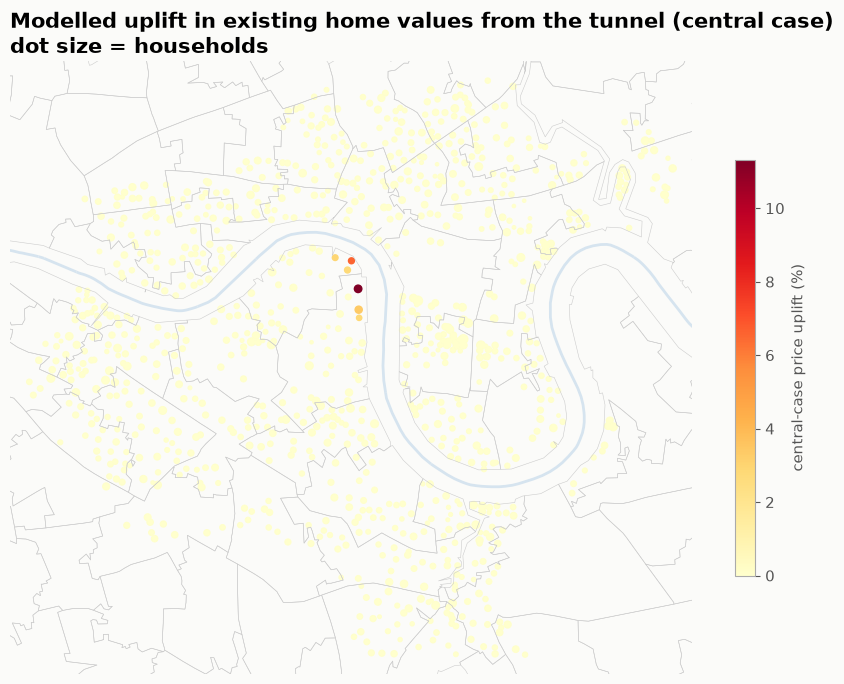

In [ ]:
fig, ax = plt.subplots(figsize=(11, 9))
oa.plot(ax=ax, column=100 * oa.uplift_pct_Central, cmap="YlOrRd", markersize=oa.households / 8, legend=True, vmin=0,
        legend_kwds={"label": "central-case price uplift (%)", "shrink": 0.6})  # fmt: skip
msoa.boundary.plot(ax=ax, color="#ccc", linewidth=0.4)
thames().plot(ax=ax, color=COLOURS["water"], linewidth=2)
xmin, ymin, xmax, ymax = oa.total_bounds
ax.set(xlim=(xmin - 200, xmax + 200), ylim=(ymin - 200, ymax + 200))
ax.set_axis_off()
ax.set_title("Modelled uplift in existing home values from the tunnel (central case)\ndot size = households")
fig.savefig(FIGURES / "uplift_map.png")